# Module 6 - TwoLayerNet with numerical gradients

This uses the `TwoLayerNet` class from lecture (sigmoid hidden layer, softmax output, cross-entropy loss). Instead of backprop, the gradient for each weight is estimated with a central difference:

$$\frac{\partial L}{\partial w} \approx \frac{L(w+h) - L(w-h)}{2h}, \quad h = 10^{-4}$$

I trained one network on Iris and one on MNIST, both with `numerical_gradient()`.

In [1]:
import os
# numpy runs faster here on one thread since the matrices are small
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
import gzip
import pickle
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
LAST_NAME = "bandar"
IRIS_MODEL = f"{LAST_NAME}_iris_nn_model.pkl"
MNIST_MODEL = f"{LAST_NAME}_mnist_nn_model.pkl"
np.random.seed(42)

## TwoLayerNet class

Same as the lecture version, I just added `accuracy()`.

In [2]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        # small random weights, zero biases
        self.params = {}
        self.params["w1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)
    def sigmoid(self, s):
        return 1 / (1 + np.exp(-s))
    def softmax(self, s):
        # subtract the max first so exp doesn't overflow
        if s.ndim == 1:
            s = s - np.max(s)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s)
        s = s - np.max(s, axis=1, keepdims=True)
        exp_s = np.exp(s)
        return exp_s / np.sum(exp_s, axis=1, keepdims=True)
    def predict(self, x):
        w1, w2 = self.params["w1"], self.params["w2"]
        b1, b2 = self.params["b1"], self.params["b2"]
        z1 = self.sigmoid(x @ w1 + b1)
        return self.softmax(z1 @ w2 + b2)
    def cross_entropy_error(self, y, yhat):
        # treat a single sample as a batch of 1
        if y.ndim == 1:
            y = y.reshape((1, y.size))
            yhat = yhat.reshape((1, yhat.size))
        batch_size = y.shape[0]
        return -np.sum(y * np.log(yhat + 1e-7)) / batch_size  # 1e-7 avoids log(0)
    def loss(self, x, y):
        return self.cross_entropy_error(y, self.predict(x))
    def accuracy(self, x, y):
        # labels are one-hot, so compare argmaxes
        return np.mean(np.argmax(self.predict(x), axis=1) == np.argmax(y, axis=1))
    def numerical_gradient(self, x, y):
        h = 1e-4
        grad = {}
        for k in self.params.keys():
            grad[k] = np.zeros_like(self.params[k])
            # nditer lets me visit every element no matter the array shape
            iter = np.nditer(self.params[k], flags=["multi_index"], op_flags=["readwrite"])
            while not iter.finished:
                idx = iter.multi_index
                tmp = self.params[k][idx]
                # nudge the weight up and down and see how the loss changes
                self.params[k][idx] = tmp + h
                fh1 = self.loss(x, y)
                self.params[k][idx] = tmp - h
                fh2 = self.loss(x, y)
                grad[k][idx] = (fh1 - fh2) / (2 * h)
                self.params[k][idx] = tmp  # put it back
                iter.iternext()
        return grad

In [3]:
def train(net, x_train, y_train, x_eval, y_eval, iters, lr, batch_size=None, log_every=100):
    # if batch_size is None, every step uses the whole training set
    history = {"iter": [], "loss": [], "train_acc": [], "test_acc": []}
    start = time.time()
    for i in range(1, iters + 1):
        if batch_size is None:
            xb, yb = x_train, y_train
        else:
            idx = np.random.choice(len(x_train), batch_size)
            xb, yb = x_train[idx], y_train[idx]
        grad = net.numerical_gradient(xb, yb)
        for k in net.params:
            net.params[k] -= lr * grad[k]
        # print progress every so often so I can watch it train
        if i % log_every == 0 or i == 1:
            history["iter"].append(i)
            history["loss"].append(net.loss(x_train, y_train))
            history["train_acc"].append(net.accuracy(x_train, y_train))
            history["test_acc"].append(net.accuracy(x_eval, y_eval))
            print(f"iter {i:5d} | loss {history['loss'][-1]:.4f} | train acc {history['train_acc'][-1]:.4f}"
                  f" | test acc {history['test_acc'][-1]:.4f} | {time.time() - start:.0f}s")
    return history
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(history["iter"], history["loss"])
    axes[0].set_title(f"{title} - training loss")
    axes[0].set_xlabel("iteration")
    axes[1].plot(history["iter"], history["train_acc"], label="train")
    axes[1].plot(history["iter"], history["test_acc"], label="test")
    axes[1].set_title(f"{title} - accuracy")
    axes[1].set_xlabel("iteration")
    axes[1].legend()
    fig.tight_layout()
    plt.show()

# Part 1: Iris

Iris has 150 flowers with 4 features each and 3 species. I save it to `iris.csv` and split it 80/20 into `iris_train.csv` and `iris_test.csv`, keeping the same mix of species in both.

In [4]:
iris = load_iris(as_frame=True)
iris_df = iris.frame.rename(columns={"target": "class_id"})
iris_df["species"] = iris_df["class_id"].map(dict(enumerate(iris.target_names)))
iris_df.to_csv("iris.csv", index=False)
# stratify so each species shows up in the same ratio in train and test
iris_train_df, iris_test_df = train_test_split(iris_df, test_size=0.2, stratify=iris_df["class_id"], random_state=42)
iris_train_df.to_csv("iris_train.csv", index=False)
iris_test_df.to_csv("iris_test.csv", index=False)
IRIS_FEATURES = iris.feature_names
IRIS_CLASSES = list(iris.target_names)
print(f"train: {len(iris_train_df)}, test: {len(iris_test_df)}")
iris_train_df.head()

train: 120, test: 30


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class_id,species
8,4.4,2.9,1.4,0.2,0,setosa
106,4.9,2.5,4.5,1.7,2,virginica
76,6.8,2.8,4.8,1.4,1,versicolor
9,4.9,3.1,1.5,0.1,0,setosa
89,5.5,2.5,4.0,1.3,1,versicolor


## Train

iter     1 | loss 1.0892 | train acc 0.4000 | test acc 0.3333 | 0s


iter   200 | loss 0.0798 | train acc 0.9750 | test acc 0.9667 | 1s


iter   400 | loss 0.0568 | train acc 0.9750 | test acc 0.9667 | 2s


iter   600 | loss 0.0497 | train acc 0.9833 | test acc 0.9667 | 3s


iter   800 | loss 0.0461 | train acc 0.9833 | test acc 1.0000 | 5s


iter  1000 | loss 0.0440 | train acc 0.9833 | test acc 1.0000 | 6s


iter  1200 | loss 0.0427 | train acc 0.9833 | test acc 1.0000 | 7s


iter  1400 | loss 0.0417 | train acc 0.9833 | test acc 1.0000 | 8s


iter  1600 | loss 0.0409 | train acc 0.9833 | test acc 1.0000 | 10s


iter  1800 | loss 0.0403 | train acc 0.9833 | test acc 1.0000 | 11s


iter  2000 | loss 0.0398 | train acc 0.9833 | test acc 1.0000 | 12s


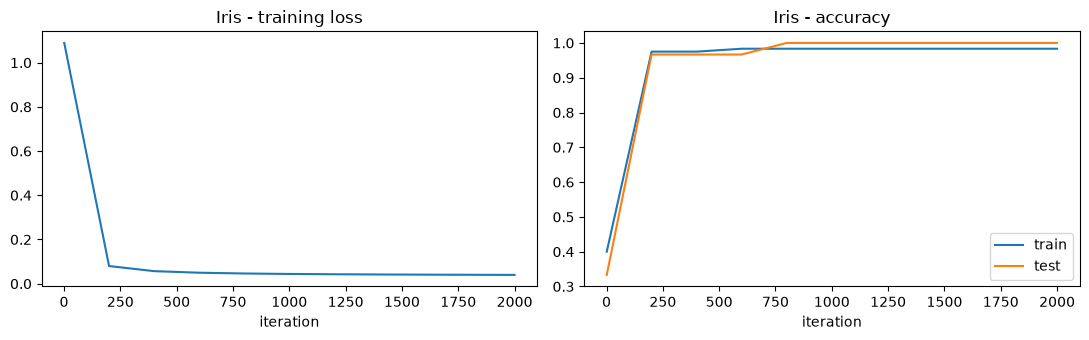

saved bandar_iris_nn_model.pkl


In [5]:
train_df = pd.read_csv("iris_train.csv")
test_df = pd.read_csv("iris_test.csv")
# standardize using only the training data, and keep mean/std on the model for testing later
x_mean = train_df[IRIS_FEATURES].to_numpy().mean(axis=0)
x_std = train_df[IRIS_FEATURES].to_numpy().std(axis=0)
x_iris_train = (train_df[IRIS_FEATURES].to_numpy() - x_mean) / x_std
x_iris_test = (test_df[IRIS_FEATURES].to_numpy() - x_mean) / x_std
y_iris_train = np.eye(3)[train_df["class_id"]]
y_iris_test = np.eye(3)[test_df["class_id"]]
iris_net = TwoLayerNet(input_size=4, hidden_size=10, output_size=3, weight_init_std=0.1)
iris_net.x_mean, iris_net.x_std, iris_net.class_names = x_mean, x_std, IRIS_CLASSES
iris_history = train(iris_net, x_iris_train, y_iris_train, x_iris_test, y_iris_test,
                     iters=2000, lr=1.0, log_every=200)
plot_history(iris_history, "Iris")
with open(IRIS_MODEL, "wb") as f:
    pickle.dump(iris_net, f)
print("saved", IRIS_MODEL)

## Test

Load the saved model back in and check every test flower.

In [6]:
with open(IRIS_MODEL, "rb") as f:
    iris_model = pickle.load(f)
test_df = pd.read_csv("iris_test.csv")
x = (test_df[IRIS_FEATURES].to_numpy() - iris_model.x_mean) / iris_model.x_std
pred = np.argmax(iris_model.predict(x), axis=1)
iris_results = pd.DataFrame({
    "actual": [iris_model.class_names[c] for c in test_df["class_id"]],
    "predicted": [iris_model.class_names[c] for c in pred],
    "result": np.where(pred == test_df["class_id"], "correct", "incorrect"),
})
print(iris_results.to_string())
print(f"\nIris test accuracy: {(iris_results['result'] == 'correct').mean():.4f} "
      f"({(iris_results['result'] == 'correct').sum()}/{len(iris_results)})")

        actual   predicted   result
0       setosa      setosa  correct
1    virginica   virginica  correct
2   versicolor  versicolor  correct
3   versicolor  versicolor  correct
4       setosa      setosa  correct
5   versicolor  versicolor  correct
6       setosa      setosa  correct
7       setosa      setosa  correct
8    virginica   virginica  correct
9   versicolor  versicolor  correct
10   virginica   virginica  correct
11   virginica   virginica  correct
12   virginica   virginica  correct
13  versicolor  versicolor  correct
14      setosa      setosa  correct
15      setosa      setosa  correct
16      setosa      setosa  correct
17  versicolor  versicolor  correct
18  versicolor  versicolor  correct
19   virginica   virginica  correct
20      setosa      setosa  correct
21   virginica   virginica  correct
22  versicolor  versicolor  correct
23   virginica   virginica  correct
24   virginica   virginica  correct
25  versicolor  versicolor  correct
26  versicolor  versicolor  

# Part 2: MNIST

MNIST has 60,000 training and 10,000 test images of handwritten digits (28x28). I load them from the original `.gz` files in `mnist/`, scale the pixels to 0-1, and flatten each image into 784 inputs.

In [7]:
def load_mnist_images(file_name):
    # skip the 16-byte header, then each image is 784 bytes
    with gzip.open(file_name, "rb") as f:
        return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784)
def load_mnist_labels(file_name):
    # label files have an 8-byte header
    with gzip.open(file_name, "rb") as f:
        return np.frombuffer(f.read(), np.uint8, offset=8)
x_mnist_train = load_mnist_images("mnist/train-images-idx3-ubyte.gz") / 255.0
t_mnist_train = load_mnist_labels("mnist/train-labels-idx1-ubyte.gz")
x_mnist_test = load_mnist_images("mnist/t10k-images-idx3-ubyte.gz") / 255.0
t_mnist_test = load_mnist_labels("mnist/t10k-labels-idx1-ubyte.gz")
y_mnist_train = np.eye(10)[t_mnist_train]
y_mnist_test = np.eye(10)[t_mnist_test]
print("train:", x_mnist_train.shape, "test:", x_mnist_test.shape)

train: (60000, 784) test: (10000, 784)


## Train

The network is 784 inputs, 10 hidden units, and 10 outputs, which is 7,960 parameters. The numerical gradient has to run the network twice for every parameter, so one step takes about 2 seconds. That's why I kept the network small and only trained for 800 steps (batch size 100, learning rate 1.0). It takes around 30 minutes.

iter     1 | loss 2.3086 | train acc 0.1124 | test acc 0.1135 | 2s


iter    50 | loss 1.6869 | train acc 0.5077 | test acc 0.5085 | 136s


iter   100 | loss 0.9352 | train acc 0.7277 | test acc 0.7295 | 228s


iter   150 | loss 0.6632 | train acc 0.8122 | test acc 0.8192 | 321s


iter   200 | loss 0.5104 | train acc 0.8795 | test acc 0.8813 | 415s


iter   250 | loss 0.4407 | train acc 0.8906 | test acc 0.8910 | 508s


... (7 outputs left out)

iter   650 | loss 0.3170 | train acc 0.9097 | test acc 0.9083 | 1232s


iter   700 | loss 0.3256 | train acc 0.9065 | test acc 0.9065 | 1341s


iter   750 | loss 0.3129 | train acc 0.9105 | test acc 0.9122 | 1450s


iter   800 | loss 0.3046 | train acc 0.9128 | test acc 0.9101 | 1555s


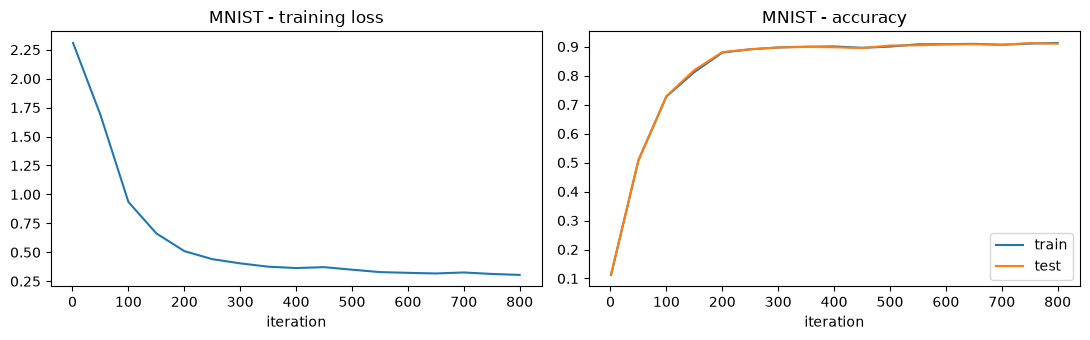

saved bandar_mnist_nn_model.pkl


In [8]:
mnist_net = TwoLayerNet(input_size=784, hidden_size=10, output_size=10)
mnist_history = train(mnist_net, x_mnist_train, y_mnist_train, x_mnist_test, y_mnist_test,
                      iters=800, lr=1.0, batch_size=100, log_every=50)
plot_history(mnist_history, "MNIST")
with open(MNIST_MODEL, "wb") as f:
    pickle.dump(mnist_net, f)
print("saved", MNIST_MODEL)

## Test

Load the saved model back in and run it on all 10,000 test images.

In [9]:
with open(MNIST_MODEL, "rb") as f:
    mnist_model = pickle.load(f)
mnist_pred = np.argmax(mnist_model.predict(x_mnist_test), axis=1)
print(f"MNIST test accuracy: {np.mean(mnist_pred == t_mnist_test):.4f} "
      f"({np.sum(mnist_pred == t_mnist_test)}/{len(t_mnist_test)})")
# show the first 25 so it's easy to compare actual vs predicted
mnist_results = pd.DataFrame({
    "actual": t_mnist_test[:25],
    "predicted": mnist_pred[:25],
    "result": np.where(mnist_pred[:25] == t_mnist_test[:25], "correct", "incorrect"),
})
print("\nFirst 25 test samples:")
print(mnist_results.to_string())

MNIST test accuracy: 0.9101 (9101/10000)

First 25 test samples:
    actual  predicted     result
0        7          7    correct
1        2          2    correct
2        1          1    correct
3        0          0    correct
4        4          4    correct
5        1          1    correct
6        4          4    correct
7        9          9    correct
8        5          6  incorrect
9        9          9    correct
10       0          0    correct
11       6          6    correct
12       9          9    correct
13       0          0    correct
14       1          1    correct
15       5          5    correct
16       9          9    correct
17       7          7    correct
18       3          3    correct
19       4          4    correct
20       9          9    correct
21       6          6    correct
22       6          6    correct
23       5          5    correct
24       4          4    correct


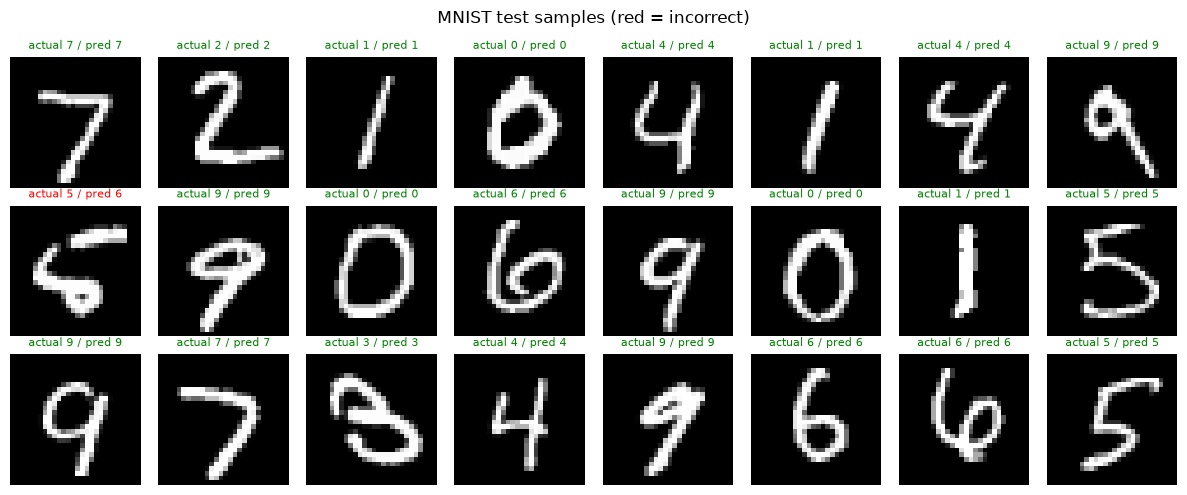

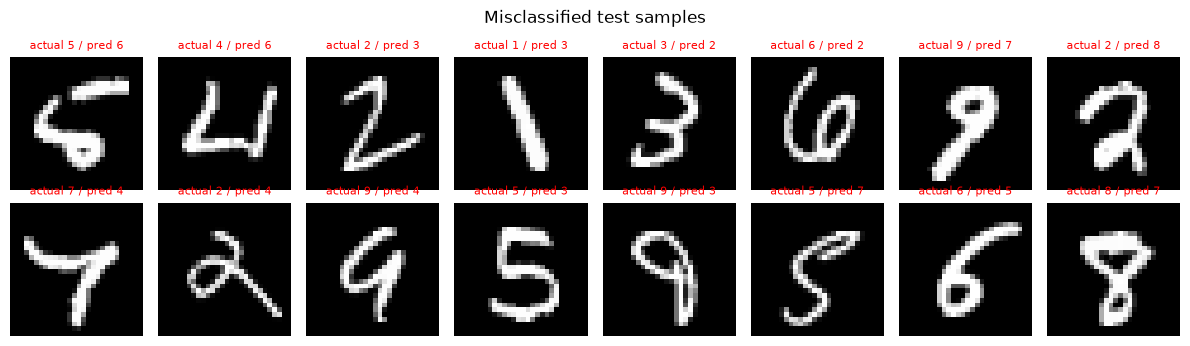

 digit  accuracy
     0    0.9776
     1    0.9744
     2    0.8983
     3    0.9089
     4    0.9358
     5    0.8318
     6    0.9144
     7    0.9416
     8    0.8604
     9    0.8414


In [10]:
# first 24 test images, wrong ones in red
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_mnist_test[i].reshape(28, 28), cmap="gray")
    ok = mnist_pred[i] == t_mnist_test[i]
    ax.set_title(f"actual {t_mnist_test[i]} / pred {mnist_pred[i]}", fontsize=8, color="green" if ok else "red")
    ax.axis("off")
fig.suptitle("MNIST test samples (red = incorrect)")
fig.tight_layout()
plt.show()
# some of the ones it got wrong
wrong = np.flatnonzero(mnist_pred != t_mnist_test)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, wrong[:16]):
    ax.imshow(x_mnist_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"actual {t_mnist_test[i]} / pred {mnist_pred[i]}", fontsize=8, color="red")
    ax.axis("off")
fig.suptitle("Misclassified test samples")
fig.tight_layout()
plt.show()
# accuracy for each digit
per_class = [np.mean(mnist_pred[t_mnist_test == d] == d) for d in range(10)]
print(pd.DataFrame({"digit": range(10), "accuracy": np.round(per_class, 4)}).to_string(index=False))

## Summary

- Both networks were trained only with numerical gradients, saved with `pickle`, loaded back, and tested on data they hadn't seen.
- Iris got every test flower right. MNIST got about 91%, which is decent for a tiny 10-unit hidden layer and less than 2 epochs of training.
- The big downside is speed. Numerical gradients need 2 forward passes per parameter for every step, so even this small MNIST network took around 30 minutes. Backprop would get the same gradient with about one forward and one backward pass.